# Bayesian survival analysis of a randomized trial

How much longer does a treatment keep patients event-free? In this tutorial we fit a Bayesian Weibull proportional hazards model to a simulated two-arm trial and answer that question with the difference in *restricted mean survival time* (RMST), together with its full posterior uncertainty. The prior definition and sampling are done in NumPyro; survjax supplies the censored-data likelihood and turns the posterior draws into survival curves and RMST. Because we simulated the trial, we can compare the posterior with the truth.

Instructions for running the notebook are at the end.

In [1]:
import numpyro

numpyro.set_host_device_count(4)  # one CPU device per chain; must run before JAX starts

import jax

jax.config.update("jax_enable_x64", True)  # the simulated trial is generated in float64

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as distributions
from numpyro.infer import MCMC, NUTS, Predictive

import survjax

NUM_DRAWS = 1000  # warmup and retained draws per chain; 100 for a quick run

/Users/wamster3/dev/survjax/dev-bayesian-use-case/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/wamster3/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/lz/l2_06bbx7fn4z318dtwnb3x40000gp/T/matplotlib-kzm64__d because there was an issue with the default path (/Users/wamster3/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


## The model

Each patient $i$ is randomized to control ($a_i=0$) or treatment ($a_i=1$). Event times follow a Weibull proportional hazards model,

$$
S(t\mid a)=\exp\!\Big[-(t/b_0)^k\,e^{\gamma a}\Big],
$$

with shape $k$, control scale $b_0$ and log hazard ratio $\gamma$; the hazard ratio of treatment versus control is $e^\gamma$. As is typical in survival analysis, some patients are still event-free when follow-up ends. For patient $i$ we observe $t_i=\min(T_i, C_i)$ and the event indicator $\delta_i$. An observed event contributes the density $f(t_i)$, a censored observation contributes the survival probability $S(t_i)$, and with independent, non-informative censoring the log likelihood is

$$
\ell(k, b_0, \gamma)=\sum_{i}\Big[\delta_i\log f(t_i\mid a_i)+(1-\delta_i)\log S(t_i\mid a_i)\Big].
$$

survjax computes the terms of this sum, one per patient, with `dist.log_likelihood(data)`; `data` is a `survjax.SurvivalData` container holding the times and event indicators.

## A simulated trial where we know the answer

The trial has 300 patients, 150 per arm. The true shape is $k=1.38$, the control scale $b_0=11.42$ years and the hazard ratio 0.7, so treatment lowers the hazard by 30% at every time. Censoring times are Uniform$(0, c)$, with $c=20$ years; about 53% of patients are censored in expectation.

In [2]:
# Same inverse-Weibull draw and key as the shared demo generator.
# Fixed 20-year Uniform censoring limit, also recorded by the runner.
shape, control_scale, hazard_ratio = 1.38, 11.42, 0.7
censor_limit = 20.0
arm = jnp.repeat(jnp.array([0.0, 1.0]), 150)
eta = jnp.log(hazard_ratio) * arm
# Match the shared generator's dtype promotion before numerical operations.
k, b, c, eta = jnp.broadcast_arrays(
    *(jnp.asarray(v, dtype=arm.dtype) for v in (shape, control_scale, censor_limit, eta))
)
scale = b * jnp.exp(-eta / k)
trial_key = jax.random.fold_in(jax.random.fold_in(jax.random.key(20261025), 2), 0)
event_key, censor_key = jax.random.split(trial_key)
u = jax.random.uniform(event_key, arm.shape, dtype=arm.dtype)
event_time = scale * (-jnp.log(u)) ** (1 / k)
censor_time = c * jax.random.uniform(censor_key, arm.shape, dtype=arm.dtype)
data = survjax.SurvivalData(jnp.minimum(event_time, censor_time), event_time <= censor_time)
data.issues.raise_if_invalid()
print(f"c = {censor_limit:.1f} years; {int((~data.exact).sum())} of {len(data)} patients censored")

c = 20.0 years; 157 of 300 patients censored


A hazard ratio is hard to translate into time gained. RMST is easier: it is the expected event-free time within a horizon $\tau$, the area under the survival curve up to $\tau$,

$$
\mathrm{RMST}(\tau)=\operatorname{E}[\min(T,\tau)]=\int_0^\tau S(t)\,dt.
$$

The difference between the arms, $\Delta\mathrm{RMST}(\tau)$, is measured in years and does not rely on proportional hazards to be interpretable. We use $\tau=5$ years. survjax evaluates RMST in closed form for the Weibull and its proportional hazards version. For the true model:

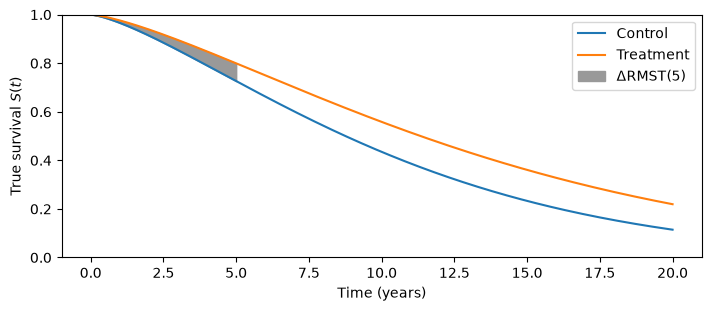

True RMST(5): control 4.391, treatment 4.561, difference 0.170 years


In [3]:
both_arms = jnp.array([0.0, 1.0])  # control, treatment
truth = survjax.ProportionalHazards(
    baseline=survjax.Weibull(shape=1.38, scale=11.42), log_hazard_ratio=jnp.log(0.7) * both_arms
)
times = jnp.linspace(0, 20, 201)
curves = truth.survival_grid(times)  # grid shape: (time, arm)

fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.plot(times, curves, label=["Control", "Treatment"])
up_to_5 = times <= 5
ax.fill_between(times[up_to_5], curves[up_to_5, 0], curves[up_to_5, 1], color="0.6",
                label="ΔRMST(5)")
ax.set(xlabel="Time (years)", ylabel="True survival $S(t)$", ylim=(0, 1))
ax.legend()
plt.show()

true_rmst5 = truth.rmst(5.0)
print(f"True RMST(5): control {true_rmst5[0]:.3f}, treatment {true_rmst5[1]:.3f}, "
      f"difference {true_rmst5[1] - true_rmst5[0]:.3f} years")

Over the first five years, treated patients gain on average 0.17 years, about two months, of event-free time. Most patients in both arms are still event-free at five years, which is why the difference is small compared to the horizon.

## The likelihood as a NumPyro factor

We define a model in NumPyro that samples the three parameters on the log scale, builds the survjax survival distribution, and adds the per-patient log likelihood to the target with `numpyro.factor`. The factor receives the vector of 300 terms, one per patient, inside the observation plate, which tells NumPyro that the terms are conditionally independent. Edit the priors here to see how they change the results.

The optional `compute_rmst` branch declares the per-arm RMST as deterministic sites; we come back to it below.

The likelihood already uses JAX array operations over all patients; the plate records conditional independence and the observation axis for NumPyro's shape and subsampling bookkeeping. It does not vectorize this calculation. Keep the `(N,)` vector inside the plate: for three terms `[-1, -2, -3]`, the joint contribution is `-6`. Passing `.sum()` inside a size-three plate broadcasts `-6` to three entries and contributes `-18`. A summed factor outside the plate gives the same full-data posterior as the vector factor inside it:

```python
# Alternative full-data factor, outside any observation plate:
numpyro.factor("survival", survival.log_likelihood(data).sum())
```

For methods supporting minibatches, such as SVI, `with numpyro.plate("observations", N, subsample_size=B) as idx:` provides indices. Explicitly use `arm[idx]` (or `X[idx]`) to construct the distribution and `data[idx]` in the likelihood, yielding `(B,)` terms. NumPyro supplies the `N / B` scale; do not multiply again. Our NUTS run uses full data. See [NumPyro's plate documentation](https://num.pyro.ai/en/stable/primitives.html#plate).

When translating the baseline, NumPyro uses `distributions.Weibull(scale=b0, concentration=k)`: its positional order is scale, shape, whereas survjax uses shape, scale. Prefer keywords.

In [4]:
def model(data, arm, compute_rmst=False, tau=5.0, tau_grid=None):
    log_k = numpyro.sample("log_k", distributions.Normal(0, 5))
    log_b0 = numpyro.sample("log_b0", distributions.Normal(0, 5))
    gamma = numpyro.sample("gamma", distributions.Normal(0, 5))

    base = survjax.Weibull.from_log(log_shape=log_k, log_scale=log_b0)
    survival = survjax.ProportionalHazards(baseline=base, log_hazard_ratio=gamma * arm)
    with numpyro.plate("observations", len(data)):
        numpyro.factor("survival", survival.log_likelihood(data))

    if compute_rmst:
        per_arm = survjax.ProportionalHazards(baseline=base, log_hazard_ratio=gamma * jnp.array([0.0, 1.0]))
        numpyro.deterministic("rmst_tau", per_arm.rmst(tau))                  # (2,)
        numpyro.deterministic("rmst_curve", per_arm.rmst(tau_grid[:, None]))  # (m, 2)

NumPyro then samples the posterior with NUTS: four chains, each with `NUM_DRAWS` warmup and `NUM_DRAWS` retained draws. Check that there are no divergent transitions, that $\hat R$ is close to 1 and that the effective sample sizes (`n_eff`) are large.

In [5]:
mcmc = MCMC(NUTS(model), num_warmup=NUM_DRAWS, num_samples=NUM_DRAWS, num_chains=4,
            progress_bar=False)
mcmc.run(jax.random.key(1), data, arm)
mcmc.print_summary()  # also reports the number of divergent transitions
samples = mcmc.get_samples()  # {"log_k": (S,), "log_b0": (S,), "gamma": (S,)}


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     gamma     -0.18      0.17     -0.19     -0.45      0.09   2293.00      1.00
    log_b0      2.48      0.09      2.47      2.33      2.62   2310.18      1.00
     log_k      0.27      0.07      0.27      0.16      0.38   2805.43      1.00

Number of divergences: 0


## The posterior is a batch of distributions

The posterior is a set of $S$ draws of $(k, b_0, \gamma)$; with the default settings $S=4{,}000$. In survjax a distribution with array-valued parameters is a batch of distributions, so we can create one distribution with the draws and treatment arm ($a=0, a=1$) and get batch shape (draw, arm):

`get_samples()` flattens chains into the draw axis; keep chain-grouped draws for convergence diagnostics. Each `[:, None]` changes `(S,)` to `(S, 1)`, so it broadcasts with two arm indicators to `(S, 2)`. Columns 0 and 1 mean control and treatment. Neither axis represents patients.

In [6]:
base = survjax.Weibull.from_log(
    log_shape=samples["log_k"][:, None], log_scale=samples["log_b0"][:, None]
)
posterior = survjax.ProportionalHazards(
    baseline=base, log_hazard_ratio=samples["gamma"][:, None] * jnp.array([0.0, 1.0])
)
rmst5 = posterior.rmst(5.0)          # (S, 2)
delta5 = rmst5[:, 1] - rmst5[:, 0]   # paired within each draw, (S,)

low, high = jnp.quantile(delta5, jnp.array([0.025, 0.975]))
print(f"ΔRMST(5): mean {delta5.mean():.3f} years, 95% interval [{low:.3f}, {high:.3f}]")
print(f"P(ΔRMST(5) > 0) = {(delta5 > 0).mean():.3f}")

ΔRMST(5): mean 0.098 years, 95% interval [-0.077, 0.272]
P(ΔRMST(5) > 0) = 0.865


To propagate the uncertainty correctly, we compute every summary within each draw, keep the two arms of a draw paired, and summarize only at the end: the posterior mean, credible interval and $P(\Delta\mathrm{RMST}(5)>0)$ are all summaries of the values in `delta5`.

The same quantities can also be declared inside the model, as deterministic sites. The `compute_rmst` flag keeps them out of the sampler, where they are not needed, and NumPyro's `Predictive` fills them in afterwards for every posterior draw. Both routes give the same values.

These sites stay outside the observation plate because they summarize arms. The optional route below checks scalar-horizon RMST; the main route remains the batched distribution above. The command-line runner also compares the horizon curves: `Predictive` returns `(S, horizon, 2)`, which requires swapping axes 0 and 1 to match the batched route.

In [7]:
tau_grid = jnp.linspace(0.0, 13.5, 101)  # horizons up to about the 90th percentile of follow-up
predictive = Predictive(model, posterior_samples=samples, return_sites=["rmst_tau"])
sites = predictive(jax.random.key(0), data, arm, compute_rmst=True, tau_grid=tau_grid)
print("Largest difference between the routes:", float(jnp.abs(sites["rmst_tau"] - rmst5).max()), "years")

Largest difference between the routes: 1.3322676295501878e-14 years


## Results

The posterior summaries, with the true values:

In [8]:
summaries = {
    "Shape k": (jnp.exp(samples["log_k"]), 1.38),
    "Hazard ratio": (jnp.exp(samples["gamma"]), 0.7),
    "RMST(5), control": (rmst5[:, 0], true_rmst5[0]),
    "RMST(5), treatment": (rmst5[:, 1], true_rmst5[1]),
    "ΔRMST(5)": (delta5, true_rmst5[1] - true_rmst5[0]),
}
print(f"{'':20}{'truth':>8}{'mean':>8}{'sd':>8}   95% credible interval")
for name, (values, true_value) in summaries.items():
    low, high = jnp.quantile(values, jnp.array([0.025, 0.975]))
    print(f"{name:20}{true_value:8.3f}{values.mean():8.3f}{values.std(ddof=1):8.3f}   "
          f"[{low:.3f}, {high:.3f}]")

                       truth    mean      sd   95% credible interval
Shape k                1.380   1.308   0.087   [1.141, 1.485]
Hazard ratio           0.700   0.844   0.143   [0.604, 1.161]
RMST(5), control       4.391   4.362   0.087   [4.179, 4.522]
RMST(5), treatment     4.561   4.460   0.076   [4.302, 4.598]
ΔRMST(5)               0.170   0.098   0.090   [-0.077, 0.272]


The posterior survival curves per arm, with 95% pointwise credible bands, the true curves and the observed Kaplan–Meier curves. The Kaplan–Meier estimate is a small helper written here; it is not part of survjax.

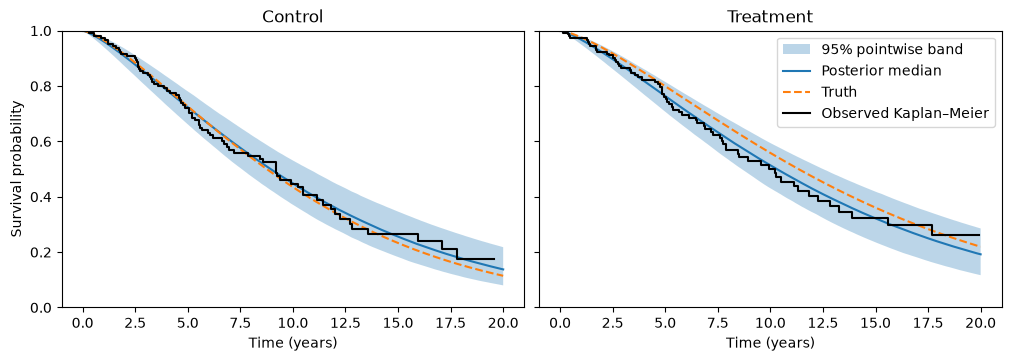

In [9]:
def kaplan_meier(time, event):
    # Product-limit estimate as step coordinates; censorings tied with an event stay at risk.
    time, event = np.asarray(time), np.asarray(event)
    event_times = np.unique(time[event])
    deaths = np.array([np.sum((time == t) & event) for t in event_times])
    at_risk = np.array([np.sum(time >= t) for t in event_times])
    survival = np.cumprod(1 - deaths / at_risk)
    return np.r_[0.0, event_times, time.max()], np.r_[1.0, survival, survival[-1]]


survival = posterior.survival_grid(times)  # (time, S, 2)
low, median, high = jnp.quantile(survival, jnp.array([0.025, 0.5, 0.975]), axis=1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True, layout="constrained")
for a, (ax, label) in enumerate(zip(axes, ["Control", "Treatment"], strict=True)):
    ax.fill_between(times, low[:, a], high[:, a], alpha=0.3, label="95% pointwise band")
    ax.plot(times, median[:, a], label="Posterior median")
    ax.plot(times, curves[:, a], "--", color="C1", label="Truth")
    ax.step(*kaplan_meier(data.lower[arm == a], data.exact[arm == a]), where="post",
            color="black", label="Observed Kaplan–Meier")
    ax.set(title=label, xlabel="Time (years)", ylim=(0, 1))
axes[0].set_ylabel("Survival probability")
axes[1].legend()
plt.show()

The posterior distribution of $\Delta\mathrm{RMST}(5)$, with its 95% credible interval and the true value. Positive values favour treatment.

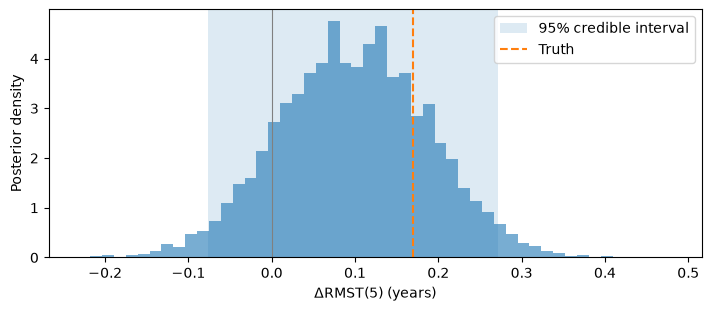

In [10]:
low, high = jnp.quantile(delta5, jnp.array([0.025, 0.975]))
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.hist(delta5, bins=50, density=True, alpha=0.6)
ax.axvspan(low, high, alpha=0.15, label="95% credible interval")
ax.axvline(true_rmst5[1] - true_rmst5[0], color="C1", linestyle="--", label="Truth")
ax.axvline(0, color="0.5", linewidth=0.8)
ax.set(xlabel="ΔRMST(5) (years)", ylabel="Posterior density")
ax.legend()
plt.show()

Putting the horizons on a leading axis evaluates RMST for every horizon, draw and arm at once:

`tau_grid[:, None, None]` has shape `(horizon, 1, 1)` and broadcasts against `(S, 2)`. In contrast, `survival_grid(times)` adds the leading time axis automatically. Both give `(time or horizon, S, 2)`; quantiles over `axis=1` summarize draws separately for each time and arm.

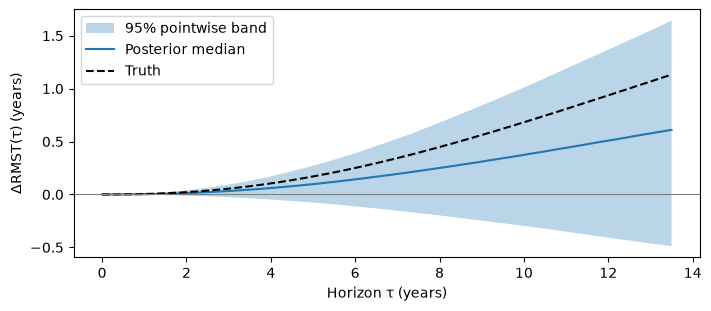

In [11]:
rmst_curve = posterior.rmst(tau_grid[:, None, None])     # (horizon, S, 2)
delta_curve = rmst_curve[..., 1] - rmst_curve[..., 0]    # (horizon, S)
low, median, high = jnp.quantile(delta_curve, jnp.array([0.025, 0.5, 0.975]), axis=1)
true_rmst = truth.rmst(tau_grid[:, None])                # (horizon, 2)

fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.fill_between(tau_grid, low, high, alpha=0.3, label="95% pointwise band")
ax.plot(tau_grid, median, label="Posterior median")
ax.plot(tau_grid, true_rmst[:, 1] - true_rmst[:, 0], "k--", label="Truth")
ax.axhline(0, color="0.5", linewidth=0.8)
ax.set(xlabel="Horizon τ (years)", ylabel="ΔRMST(τ) (years)")
ax.legend(loc="upper left")
plt.show()

To go further, add covariates to the linear predictor, `log_hazard_ratio=X @ beta`, try another baseline distribution, or report RMST at several horizons from the same draws. See the [proportional hazards](https://survjax.readthedocs.io/en/latest/proportional-hazards.html), [RMST](https://survjax.readthedocs.io/en/latest/rmst.html) and [likelihood](https://survjax.readthedocs.io/en/latest/likelihood.html) documentation.

## Running this notebook

From the repository root, run `uv run --group docs --group examples jupyter lab examples/bayesian_rmst/bayesian-rmst.ipynb`, then **Restart Kernel and Run All Cells** in a fresh Python 3 kernel. The first cell must run before JAX starts: it gives each chain its own CPU device and switches JAX to float64. Sampling takes a few seconds on a laptop CPU; set `NUM_DRAWS = 100` for a quick run. Float64 reproduces the committed simulated trial and its numerical checks; it is not a general requirement of this Weibull model or factor integration. The notebook uses a different NUTS key from the [command-line runner](https://github.com/vanamsterdam/survjax/tree/main/examples/bayesian_rmst); use that runner to reproduce the committed posterior.

This notebook can also be copied to any directory and run without a repository checkout. In a Python 3.12 environment, use `survjax==0.0.1a3`, `numpyro==0.22.0`, `matplotlib==3.11.2`, `jupyterlab==4.6.4` and `ipykernel==7.4.0`, then open it with Jupyter and run all cells. The notebook check used JAX 0.11.2 and NumPy 2.5.3; the repository lockfile records the full environment. The trial-generation cell spells out the short synthetic draw using the shared generator's key and fixed 20-year censoring limit; it imports no repository example modules. The command-line runner still uses the shared generator.

## References

Hoffman, M. D. and Gelman, A. (2014). The No-U-Turn sampler: adaptively setting path lengths in Hamiltonian Monte Carlo. *Journal of Machine Learning Research* 15, 1593–1623.

Phan, D., Pradhan, N. and Jankowiak, M. (2019). Composable effects for flexible and accelerated probabilistic programming in NumPyro. arXiv:1912.11554.

Royston, P. and Parmar, M. K. B. (2013). Restricted mean survival time: an alternative to the hazard ratio for the design and analysis of randomized trials with a time-to-event outcome. *BMC Medical Research Methodology* 13, 152.

All data in this notebook are synthetic.